In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.datasets import fetch_openml

In [2]:
titanic_data = fetch_openml("titanic", version = 1, as_frame = True) #downloading titanic dataset in pandas object

In [3]:
df = titanic_data['data']# extract feature column in dataset

In [4]:
df['survived'] = titanic_data['target'] # Append target variable ('survived') to DataFrame

In [5]:
df.head()

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,survived
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0


<Axes: xlabel='survived', ylabel='count'>

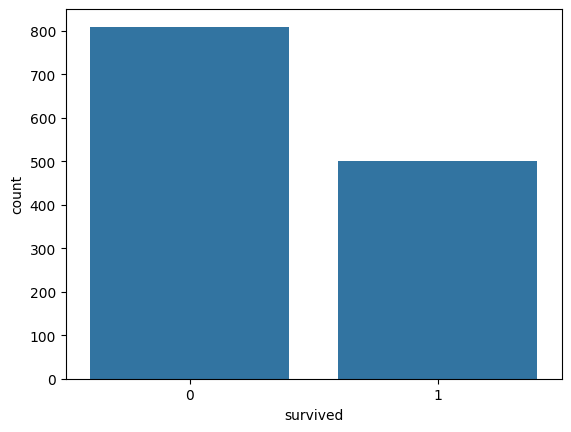

In [6]:
sns.countplot(x = 'survived', data = df)


<Axes: xlabel='survived', ylabel='count'>

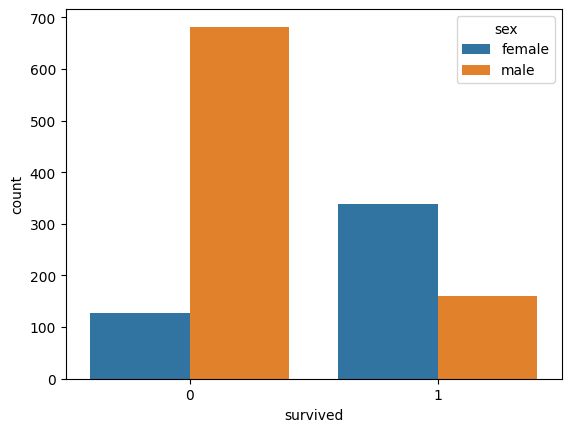

In [7]:
sns.countplot(x= 'survived' ,hue = "sex", data = df) #based on gender

<Axes: xlabel='survived', ylabel='count'>

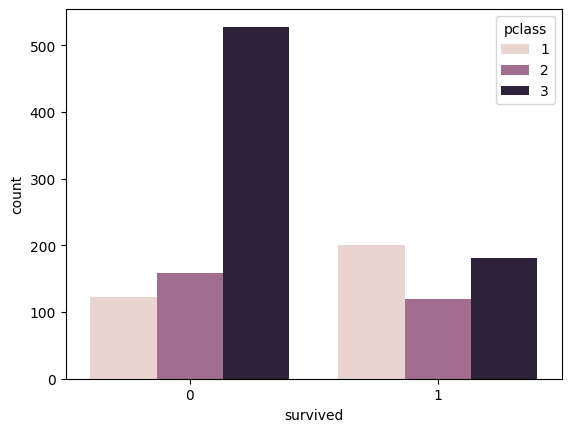

In [8]:
sns.countplot(x= 'survived' ,hue = "pclass", data = df) #based on pclass

<Axes: ylabel='Frequency'>

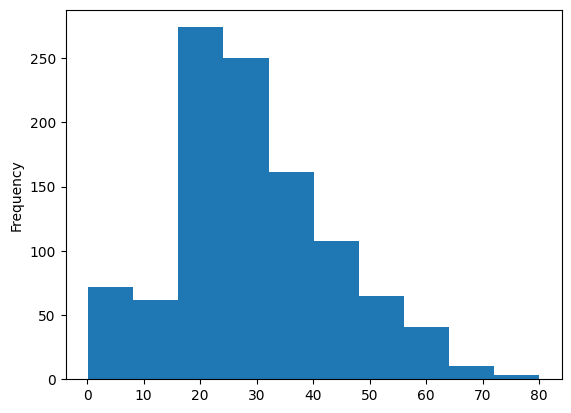

In [9]:
df['age'].plot.hist()

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   name       1309 non-null   object  
 2   sex        1309 non-null   category
 3   age        1046 non-null   float64 
 4   sibsp      1309 non-null   int64   
 5   parch      1309 non-null   int64   
 6   ticket     1309 non-null   object  
 7   fare       1308 non-null   float64 
 8   cabin      295 non-null    object  
 9   embarked   1307 non-null   category
 10  boat       486 non-null    object  
 11  body       121 non-null    float64 
 12  home.dest  745 non-null    object  
 13  survived   1309 non-null   category
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB


In [11]:
df.isnull().sum()  #sum of null values from each column

,0
pclass,0
name,0
sex,0
age,263
sibsp,0
parch,0
ticket,0
fare,1
cabin,1014
embarked,2


<Axes: title={'center': 'missing values in percentage'}, ylabel='percentage'>

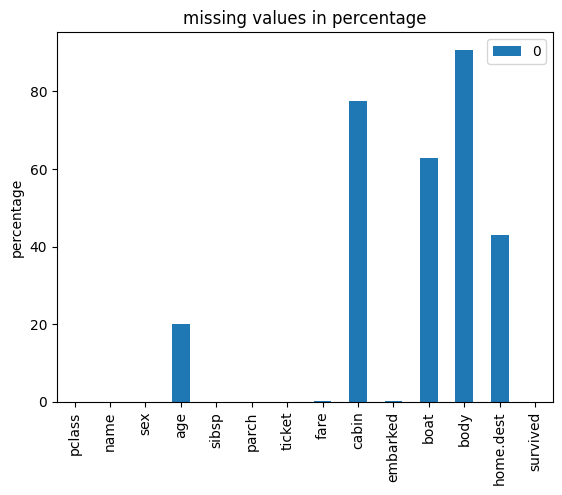

In [12]:
miss_vals = pd.DataFrame(df.isnull().sum()/len(df) * 100) #  missing val percentage
miss_vals.plot(kind = 'bar', title ='missing values in percentage' , ylabel = 'percentage')  #plotiing minisg vals

# **FEATURE ENGINEERING**

In [14]:
#to classify if a person has travelled alone or with family using Sibsp Parch column

df['family'] = df['sibsp'] + df['parch']
df.loc[df['family'] > 0, 'travelled_alone'] = 0 #with family
df.loc[df['family'] == 0, 'travelled_alone'] =1 # without family

In [15]:
df['family'].head()

,family
0,0
1,3
2,3
3,3
4,3


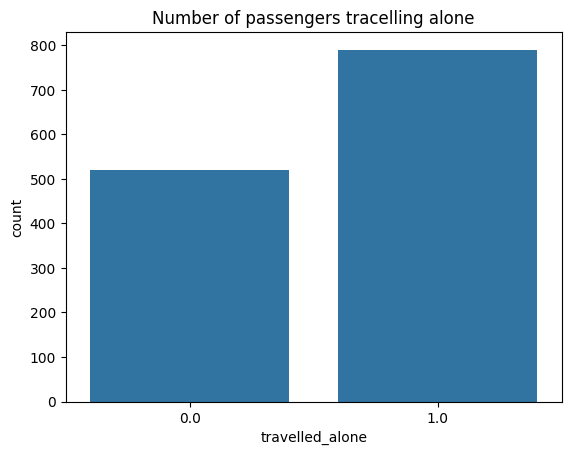

In [16]:
df.drop(['sibsp' , 'parch'], axis =1 , inplace = True)  # Drop redundant original family columns
sns.countplot(x ='travelled_alone' , data = df)
plt.title("Number of passengers tracelling alone")
plt.show()

<Axes: xlabel='survived', ylabel='count'>

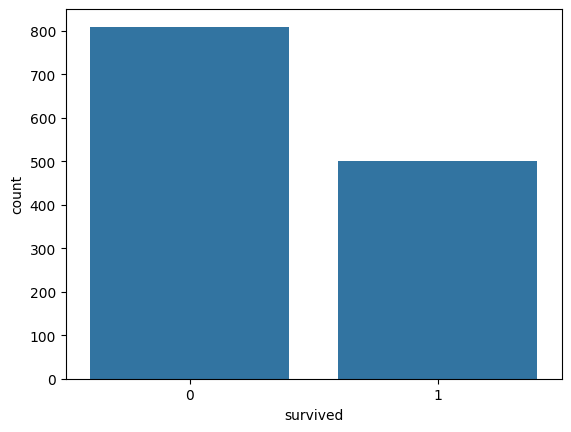

In [17]:
sns.countplot(x= "survived" , data = df)

In [18]:
df.head()

,pclass,name,sex,age,ticket,fare,cabin,embarked,boat,body,home.dest,survived,family,travelled_alone
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1,0,1.0
1,1,"Allison, Master. Hudson Trevor",male,0.9167,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1,3,0.0
2,1,"Allison, Miss. Helen Loraine",female,2.0000,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0,3,0.0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0,3,0.0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0,3,0.0


In [19]:
df.drop(['name' , 'ticket' , 'home.dest'], axis= 1, inplace =True)  # Drop non-predictive text features

In [20]:
df.head()

,pclass,sex,age,fare,cabin,embarked,boat,body,survived,family,travelled_alone
0,1,female,29.0000,211.3375,B5,S,2,NaN,1,0,1.0
1,1,male,0.9167,151.5500,C22 C26,S,11,NaN,1,3,0.0
2,1,female,2.0000,151.5500,C22 C26,S,NaN,NaN,0,3,0.0
3,1,male,30.0000,151.5500,C22 C26,S,NaN,135.0,0,3,0.0
4,1,female,25.0000,151.5500,C22 C26,S,NaN,NaN,0,3,0.0


In [21]:
df.drop(['cabin' , 'body' , 'boat'], axis= 1, inplace =True)   # Drop columns with high percentage of missing values

In [22]:
df.head()

,pclass,sex,age,fare,embarked,survived,family,travelled_alone
0,1,female,29.0000,211.3375,S,1,0,1.0
1,1,male,0.9167,151.5500,S,1,3,0.0
2,1,female,2.0000,151.5500,S,0,3,0.0
3,1,male,30.0000,151.5500,S,0,3,0.0
4,1,female,25.0000,151.5500,S,0,3,0.0


In [23]:
sex = pd.get_dummies(df['sex'], drop_first = True)  # Convert gender into binary (1 for male, 0 for female)
print(sex)  # Overwrite 'sex' column with numeric dummy representation

       male
0     False
1      True
2     False
3      True
4     False
...     ...
1304  False
1305  False
1306   True
1307   True
1308   True

[1309 rows x 1 columns]


In [24]:
df['sex']= sex

In [25]:
df.isnull().sum()

,0
pclass,0
sex,0
age,263
fare,1
embarked,2
survived,0
family,0
travelled_alone,0


In [28]:
from sklearn.impute import SimpleImputer
imp_mean = SimpleImputer(strategy = 'mean')

In [29]:
df['age'] = imp_mean.fit_transform(df[['age']])
df['fare'] = imp_mean.fit_transform(df[['fare']])

In [30]:
df.isnull().sum()

,0
pclass,0
sex,0
age,0
fare,0
embarked,2
survived,0
family,0
travelled_alone,0


In [34]:
imp_freq = SimpleImputer(strategy = 'most_frequent')


In [36]:
df['embarked'] = imp_freq.fit_transform(df[['embarked']]).ravel()

In [37]:
df.isnull().sum()

,0
pclass,0
sex,0
age,0
fare,0
embarked,0
survived,0
family,0
travelled_alone,0


In [38]:
df.head()

,pclass,sex,age,fare,embarked,survived,family,travelled_alone
0,1,False,29.0000,211.3375,S,1,0,1.0
1,1,True,0.9167,151.5500,S,1,3,0.0
2,1,False,2.0000,151.5500,S,0,3,0.0
3,1,True,30.0000,151.5500,S,0,3,0.0
4,1,False,25.0000,151.5500,S,0,3,0.0


In [42]:
embark = pd.get_dummies(df['embarked'], drop_first = True)
print(embark)

          Q      S
0     False   True
1     False   True
2     False   True
3     False   True
4     False   True
...     ...    ...
1304  False  False
1305  False  False
1306  False  False
1307  False  False
1308  False   True

[1309 rows x 2 columns]


In [43]:
df.drop(['embarked'] ,axis = 1, inplace = True)
df = pd.concat([df , embark], axis=1)

In [44]:
df.head()

,pclass,sex,age,fare,survived,family,travelled_alone,Q,S
0,1,False,29.0000,211.3375,1,0,1.0,False,True
1,1,True,0.9167,151.5500,1,3,0.0,False,True
2,1,False,2.0000,151.5500,0,3,0.0,False,True
3,1,True,30.0000,151.5500,0,3,0.0,False,True
4,1,False,25.0000,151.5500,0,3,0.0,False,True


In [46]:
x= df.drop(['survived'] , axis = 1)
x.head()

,pclass,sex,age,fare,family,travelled_alone,Q,S
0,1,False,29.0000,211.3375,0,1.0,False,True
1,1,True,0.9167,151.5500,3,0.0,False,True
2,1,False,2.0000,151.5500,3,0.0,False,True
3,1,True,30.0000,151.5500,3,0.0,False,True
4,1,False,25.0000,151.5500,3,0.0,False,True


In [47]:
y = df['survived']
y.head()

,survived
0,1
1,1
2,0
3,0
4,0


In [48]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [49]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(916, 8)
(393, 8)
(916,)
(393,)


In [50]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression()
log_model.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [53]:
pred = log_model.predict(x_test)

In [54]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, pred)

0.8091603053435115

In [55]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, pred)

array([[202,  22],
       [ 53, 116]])